In [24]:
import pandas as pd
import requests

wip


In [25]:
#Constants
PRE = list(range(1, 51))  # if t=1 is Jan 2018 and t=50 is Feb 2022
POST = list(range(51, 61)) #then we have the end of their data

#Robustness constant
POST_2023 = list(range(51,73))  # Additional post-treatment period 2023
POST_2024 = list(range(51,84))  # Additional post-treatment period 2024

In [26]:
#Imports
df_merged = pd.read_csv('Data/Clean/infant_birth_death.csv')

In [27]:
#Prepare Rates and Times
df_merged['pct_medicaid'] = df_merged['births_medicaid'] / df_merged['births'] 
df_merged['pct_35'] = df_merged['births_35'] / df_merged['births'] 
df_merged['pct_college'] = df_merged['births_college'] / df_merged['births'] 

df_merged['rate']  = (df_merged['deaths'] / df_merged['births']) * 1000
df_merged['rate_neonatal']  = (df_merged['deaths_neonatal'] / df_merged['births']) * 1000

df_merged['t'] = (df_merged['year'] - 2018)*12 + df_merged['month']
#print(df_merged.head())

In [28]:
#Limiting to those with infant mortality
infant_state_list = df_merged[df_merged['year']<=2022].groupby('state')['deaths'].min().reset_index()
infant_state_list = infant_state_list[infant_state_list['deaths'] > 0]
#print(infant_state_list)

df_infant = df_merged[(df_merged['state'].isin(infant_state_list['state']))]
#df_infant = df_merged[(df_merged['state'].isin(infant_state_list['state'])) & (df_merged['year']<=2022) ]

print(df_infant.state.unique())

infant_state_list_excl_tx = list(infant_state_list[~infant_state_list['state'].isin(['Texas'])]['state'].unique())

<ArrowStringArray>
[       'Alabama',        'Arizona',       'Arkansas',     'California',
       'Colorado',        'Florida',        'Georgia',       'Illinois',
        'Indiana',         'Kansas',       'Kentucky',      'Louisiana',
       'Maryland',  'Massachusetts',       'Michigan',      'Minnesota',
    'Mississippi',       'Missouri',     'New Jersey',       'New York',
 'North Carolina',           'Ohio',       'Oklahoma',   'Pennsylvania',
 'South Carolina',      'Tennessee',          'Texas',       'Virginia',
     'Washington',      'Wisconsin']
Length: 30, dtype: str


In [29]:
#Limiting to those with neonatal mortality
neonatal_state_list = df_merged[df_merged['year']<=2022].groupby('state')['deaths_neonatal'].min().reset_index()
neonatal_state_list = neonatal_state_list[neonatal_state_list['deaths_neonatal'] > 0]
#print(neonatal_state_list)

df_neonatal = df_merged[(df_merged['state'].isin(neonatal_state_list['state']))]
#print(df_neonatal.state.unique())

neonatal_state_list_excl_tx = list(neonatal_state_list[~neonatal_state_list['state'].isin(['Texas'])]['state'].unique())

In [30]:
#DEMEANING
pre_means = (
    df_infant[df_infant["t"].isin(PRE)]
    .groupby("state")["deaths"]
    .mean()
)

df_infant = df_infant.copy()
df_infant["deaths_fe"] = (
    df_infant["deaths"] - df_infant["state"].map(pre_means)
)

#####################################
pre_means_nn = (
    df_neonatal[df_neonatal["t"].isin(PRE)]
    .groupby("state")["deaths_neonatal"]
    .mean()
)

df_neonatal = df_neonatal.copy()
df_neonatal["deaths_fe"] = (
    df_neonatal["deaths_neonatal"] - df_neonatal["state"].map(pre_means_nn)
)

In [31]:
#Data Prep - Infant
from pysyncon import Dataprep, AugSynth
PRE = range(1,51)

dataprep = Dataprep(
    foo=df_infant,
    predictors=[
        "pct_medicaid",
        'pct_35',
        'pct_college'
    ],
    predictors_op="mean",
    time_predictors_prior=PRE,
    dependent="deaths_fe",
    unit_variable="state",
    time_variable="t",
    treatment_identifier="Texas",
    controls_identifier=infant_state_list_excl_tx,
    time_optimize_ssr=PRE,
)

#Weight Calculation
augsynth = AugSynth()
augsynth.fit(dataprep=dataprep,residualize = True)

In [32]:
#Data Prep - Neonatal
dataprep_nn = Dataprep(
    foo=df_neonatal,
    predictors=[
        "pct_medicaid",
        'pct_35',
        'pct_college'
    ],
    predictors_op="mean",
    time_predictors_prior=PRE,
    dependent="deaths_fe",
    unit_variable="state",
    time_variable="t",
    treatment_identifier="Texas",
    controls_identifier=neonatal_state_list_excl_tx,
    time_optimize_ssr=PRE,
)

#Weight Calculation
augsynth_nn = AugSynth()
augsynth_nn.fit(dataprep=dataprep_nn,residualize = True)

In [33]:
#Sanity Checking Weights
print(augsynth.weights().sort_values(ascending=False).head(5))
print(augsynth.weights().sum())

print(augsynth_nn.weights().sort_values(ascending=False).head(5))
print(augsynth_nn.weights().sum())

Missouri      0.402
Alabama       0.218
Florida       0.160
Georgia       0.154
Washington    0.147
Name: weights, dtype: float64
0.998
Missouri      0.221
Louisiana     0.197
Tennessee     0.170
California    0.167
Washington    0.160
Name: weights, dtype: float64
0.9989999999999999


In [34]:
#Table 2

def table2_results(synth, df, excl_list,col_birth,col_death):
    # Final ASCM weights
    w = synth.weights(round=10)
    w = w.reindex(excl_list).fillna(0)

    # Demeaned post-treatment control outcomes
    controls_post = (
        df[df["state"].isin(w.index)]
        .pivot(index="t", columns="state", values="deaths_fe")
        .reindex(POST)
    )

    synthetic_fe = controls_post @ w

    # Restore Texas's pre-treatment level
    texas_pre_mean = pre_means["Texas"]
    expected_deaths = synthetic_fe + texas_pre_mean

    texas_post = (
        df[df["state"] == "Texas"]
        .set_index("t")
        .reindex(POST)
    )

    results = texas_post[[col_death, col_birth]].copy()
    results["expected_deaths"] = expected_deaths
    results["difference"] = (
        results[col_death] - results["expected_deaths"]
    )

    results["observed_rate"] = (
        1000 * results[col_death] / results[col_birth]
    )

    results["expected_rate"] = (
        1000 * results["expected_deaths"] / results[col_birth]
    )

    results["rate_difference"] = (
        results["observed_rate"] - results["expected_rate"]
    )

    total_observed = results[col_death].sum()
    total_expected = results["expected_deaths"].sum()
    total_difference = total_observed - total_expected
    #print(results.head())

    return total_observed, total_expected, total_difference

results_infant = table2_results(augsynth, df_infant, infant_state_list_excl_tx, "births", "deaths")
results_nn = table2_results(augsynth_nn, df_neonatal, neonatal_state_list_excl_tx, "births", "deaths_neonatal")

In [35]:
#Show Result - Totals
print(results_infant)
print(results_nn)

(np.int64(1916), np.float64(1704.57062506514), np.float64(211.4293749348601))
(np.int64(1235), np.float64(1666.9484478748395), np.float64(-431.94844787483953))


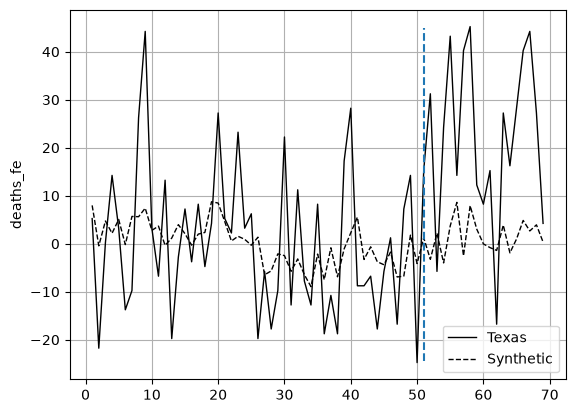

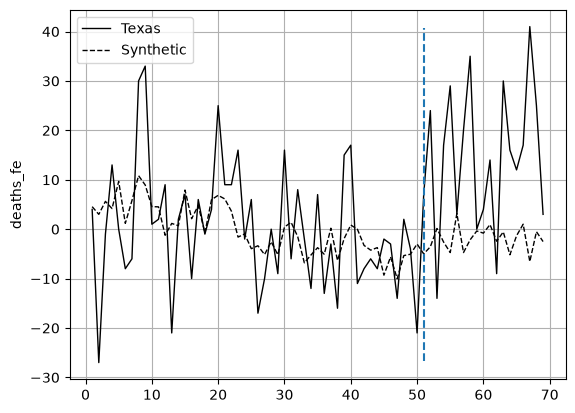

{'att': 21.142937492626025, 'se': 5.519278606027533}


In [37]:
#Plot
augsynth.path_plot(time_period = range(1,70),treatment_time = 51)
augsynth_nn.path_plot(time_period = range(1,70),treatment_time = 51)

print(augsynth.att(time_period=POST))